## 1. Setup

In [124]:
%pip install scikit-learn


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [125]:
import pandas as pd               # tables
import numpy as np                # maths
import matplotlib.pyplot as plt   # plots
import os
import glob                       # locates files with shared features (for data filtering/loading)

print(os.listdir("data"))

['.DS_Store', 'exchange_rate_2014-2017.xls', 'README.md', 'AIP_Terminal_gate_prices_Data_09-Oct-2026.xlsx', 'fuel type data', 'blacktown_u91_price_changes.csv', 'exchange_rate_2023-current.xls', 'exchange_rate_2018-2022.xls', 'DCOILBRENTEU.csv']


In [126]:
# Our study period, and what we're forecasting.
# Defining these ONCE here means every dataset gets cut to exactly the same range,
# and you could re-run the whole project for another suburb or fuel by changing one line.
START  = "2020-01-01" # fuel price data start
END    = "2026-08-31" #fuel price data end
SUBURB = "BLACKTOWN"
FUEL   = "U91"

In [127]:
#Terminal price only, remove diesel and notes sheet, focus on U91 in Sydney only
terminal_prices = pd.read_excel("data/AIP_Terminal_gate_prices_Data_09-Oct-2026.xlsx", sheet_name="Petrol TGP")
print(terminal_prices.shape)
terminal_prices.head()

(5942, 9)


,AVERAGE ULP TGPS\n(inclusive of GST),Sydney,Melbourne,Brisbane,Adelaide,Perth,Darwin,Hobart,National\nAverage
0,2004-01-01,86.3,85.1,86.4,87.2,88.5,89.7,87.9,86.4
1,2004-01-02,86.3,85.1,86.4,87.2,88.5,89.7,87.9,86.4
2,2004-01-05,86.4,85.3,86.4,87.2,89.0,89.7,87.9,86.5
3,2004-01-06,86.8,85.6,87.0,87.7,89.1,90.3,88.5,86.9
4,2004-01-07,86.7,85.5,87.0,87.7,89.1,90.3,88.5,86.8


In [128]:
terminal_prices = terminal_prices.iloc[:, [0, 1]]               # column 0 = date, column 1 = Sydney (chosen column by position (0,1))
terminal_prices.columns = ["date", "terminal_price"]           
terminal_prices.head()

,date,terminal_price
0,2004-01-01,86.3
1,2004-01-02,86.3
2,2004-01-05,86.4
3,2004-01-06,86.8
4,2004-01-07,86.7


In [129]:
# Check if data types are correct (dates as dates, prices as numbers)

terminal_prices["date"] = pd.to_datetime(terminal_prices["date"], errors="coerce") #coerce goes through all missing data and replaces with NaN
terminal_prices["terminal_price"]  = pd.to_numeric(terminal_prices["terminal_price"], errors="coerce")
terminal_prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 5942 entries, 0 to 5941
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   date            5942 non-null   datetime64[us]
 1   terminal_price  5942 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 93.0 KB


In [130]:
# Check data for missing or duplicated values (possible errors in data)
print("Missing values:\n", terminal_prices.isna().sum())
print("Duplicate dates:", terminal_prices["date"].duplicated().sum())

Missing values:
 date              0
terminal_price    0
dtype: int64
Duplicate dates: 0


In [131]:
# disregards data outside of range Jan 2020 - Aug 2026.
terminal_prices = terminal_prices[(terminal_prices["date"] >= START) & (terminal_prices["date"] <= END)]
print("Rows in study period:", len(terminal_prices))
terminal_prices.describe()

Rows in study period: 1739


,date,terminal_price
count,1739,1739.000000
mean,2023-05-01 14:23:40.126509,155.563485
min,2020-01-01 00:00:00,81.400000
25%,2021-08-31 12:00:00,138.300000
50%,2023-05-02 00:00:00,162.800000
75%,2024-12-30 12:00:00,173.000000
max,2026-08-31 00:00:00,249.000000
std,NaN,28.159798


In [132]:
# AIP publishes on business days. 0 = monday, 1 = tuesday, 2 = wednesday...
terminal_prices["date"].dt.dayofweek.value_counts().sort_index()

date
0    348
1    347
2    348
3    348
4    348
Name: count, dtype: int64

In [133]:
# Look at head of 1 file to check format of data
pd.read_excel("data/exchange_rate_2023-current.xls", header=None).iloc[:13, :3] # 13 rows (incl the heading at top), 3 columns

,0,1,2
0,F11.1 EXCHANGE RATES,NaN,NaN
1,Title,A$1=USD,Trade-weighted Index May 1970 = 100
2,Description,AUD/USD Exchange Rate; see notes for further d...,Australian Dollar Trade-weighted Index
3,Frequency,Daily,Daily
4,Type,Indicative,Indicative
5,Units,USD,Index
6,NaN,NaN,NaN
7,NaN,NaN,NaN
8,Source,WM/Reuters,RBA
9,Publication date,2026-10-09 00:00:00,2026-10-09 00:00:00


In [134]:
files = ["data/exchange_rate_2014-2017.xls", "data/exchange_rate_2018-2022.xls", "data/exchange_rate_2023-current.xls"] #combines all 3 file names and stores it into 1 list (since RBA data was split into 3 different time periods)

parts = []
for f in files:
    # reads the 3 opened files, skips the written section at the top, filters only for AUD/USD. Loop is run 3 times for each file
    part = pd.read_excel(f, header=None, skiprows=11, usecols=[0, 1], names=["date", "audusd"])
    parts.append(part)

Exc_rate = pd.concat(parts, ignore_index=True)    # stack the three files into one table
print(Exc_rate.shape)
Exc_rate.head()

(3207, 2)


,date,audusd
0,2014-01-02,0.8912
1,2014-01-03,0.8982
2,2014-01-06,0.8949
3,2014-01-07,0.8920
4,2014-01-08,0.8931


In [135]:
#same check conducted for terminal prices, missing/duplicated values are checked. Missing = NaN, duplicate checks for several instances of same date
Exc_rate["date"]   = pd.to_datetime(Exc_rate["date"], errors="coerce")
Exc_rate["audusd"] = pd.to_numeric(Exc_rate["audusd"], errors="coerce")

print("Missing values:\n", Exc_rate.isna().sum()) 
print("Duplicate dates:", Exc_rate["date"].duplicated().sum())   

Missing values:
 date      0
audusd    1
dtype: int64
Duplicate dates: 0


In [136]:
# Checks exact missing value data
Exc_rate[Exc_rate["audusd"].isna()] # value is outside of selected reporting period. 

,date,audusd
349,2015-05-25,NaN


In [137]:
#same process to terminal, minimises range to Jan 2020 - Aug 2026
Exc_rate = Exc_rate[(Exc_rate["date"] >= START) & (Exc_rate["date"] <= END)]
print("Rows in study period:", len(Exc_rate))
Exc_rate.describe()

Rows in study period: 1673


,date,audusd
count,1673,1673.000000
mean,2023-04-30 20:51:30.017931,0.686242
min,2020-01-02 00:00:00,0.557100
25%,2021-08-30 00:00:00,0.653900
50%,2023-05-03 00:00:00,0.676300
75%,2024-12-30 00:00:00,0.715900
max,2026-08-31 00:00:00,0.797000
std,NaN,0.041362


## 4. Brent crude oil price
FRED gives a simple CSV with two columns. Blank cells are days the London oil market was closed (Christmas, Easter, UK bank holidays).

In [138]:
brent = pd.read_csv("data/DCOILBRENTEU.csv")
brent.columns = ["date", "brent_usd"]      # rename the Brent price columns in the table into dates & brent (USD)
brent["date"] = pd.to_datetime(brent["date"]) # converts dates into numeric values 
brent["brent_usd"] = pd.to_numeric(brent["brent_usd"], errors="coerce") 

print(brent.shape)
print("Missing values:\n", brent.isna().sum())
print("Duplicate dates:", brent["date"].duplicated().sum())

(10275, 2)
Missing values:
 date            0
brent_usd    1173
dtype: int64
Duplicate dates: 0


In [139]:
brent = brent[(brent["date"] >= START) & (brent["date"] <= END)] # reduce period to Jan 2020 - Aug 2026
print("Rows in study period:", len(brent))
brent.describe()

Rows in study period: 1739


,date,brent_usd
count,1739,1685.000000
mean,2023-05-01 14:23:40.126509,75.848837
min,2020-01-01 00:00:00,9.120000
25%,2021-08-31 12:00:00,66.720000
50%,2023-05-02 00:00:00,76.100000
75%,2024-12-30 12:00:00,86.260000
max,2026-08-31 00:00:00,138.210000
std,NaN,20.385602


In [140]:
#creating fuel excise dataframe - roughly 2 excise changes per year excluding 2022 & 2026
excise = pd.DataFrame([
    ("2019-08-05", 41.8), #included as this excise applies to jan 2020
    ("2020-02-03", 42.3),
    ("2021-02-01", 42.7),   # no increase in Aug 2020 (-inflation)
    ("2021-08-02", 43.3),
    ("2022-02-01", 44.2),
    ("2022-03-30", 22.1),   # 2022 temporary cut: excise halved to ease petrol prices due to russia-ukraine conflict
    ("2022-08-01", 23.0),
    ("2022-09-29", 46.0),   #  temporary cut end
    ("2023-02-01", 47.7),
    ("2023-08-01", 48.8),
    ("2024-02-05", 49.6),
    ("2024-08-05", 50.6),
    ("2025-02-03", 50.8),
    ("2025-08-04", 51.6),
    ("2026-02-02", 52.6),
    ("2026-04-01", 20.6),   # 2026 cut: 60.9% reduction in response to increased petrol prices as a result iran conflict 
    ("2026-07-01", 36.6),   #  restored by 50% (30.4% reduction)
    ("2026-08-03", 53.7),   # restored by 100% (back to regular)
], columns=["date", "excise"])

excise["date"] = pd.to_datetime(excise["date"])
excise

,date,excise
0,2019-08-05,41.8
1,2020-02-03,42.3
2,2021-02-01,42.7
3,2021-08-02,43.3
4,2022-02-01,44.2
5,2022-03-30,22.1
6,2022-08-01,23.0
7,2022-09-29,46.0
8,2023-02-01,47.7
9,2023-08-01,48.8


In [141]:
#merges all separate data into a dataframe
daily = pd.DataFrame({"date": pd.date_range(START, END, freq="D")})
print("Calendar days:", len(daily))

daily = daily.merge(terminal_prices,   on="date", how="left")
daily = daily.merge(Exc_rate,    on="date", how="left")
daily = daily.merge(brent, on="date", how="left")
daily = pd.merge_asof(daily, excise, on="date")     # As its not a file and doesnt have daily changes, rather rates that are applied for periods of time, the most recent rate at the selected day is used

print("Missing BEFORE filling:\n", daily.isna().sum())

Calendar days: 2435
Missing BEFORE filling:
 date                0
terminal_price    696
audusd            762
brent_usd         750
excise              0
dtype: int64


In [142]:
cols = ["terminal_price", "audusd", "brent_usd"]
daily[cols] = daily[cols].ffill(limit=5) # all apply to business days only (max days is 5 to account for public holidays)


daily[cols] = daily[cols].bfill(limit=1) # 1st Jan 2020 is a public holiday, thus backward fill is used (Jan 1 takes jan 2 value)

print("Missing AFTER filling:\n", daily.isna().sum())
daily.head(10)

Missing AFTER filling:
 date              0
terminal_price    0
audusd            0
brent_usd         0
excise            0
dtype: int64


,date,terminal_price,audusd,brent_usd,excise
0,2020-01-01,136.0,0.7003,67.05,41.8
1,2020-01-02,136.0,0.7003,67.05,41.8
2,2020-01-03,135.6,0.6966,69.08,41.8
3,2020-01-04,135.6,0.6966,69.08,41.8
4,2020-01-05,135.6,0.6966,69.08,41.8
5,2020-01-06,134.7,0.6945,70.25,41.8
6,2020-01-07,134.1,0.6928,68.74,41.8
7,2020-01-08,134.2,0.6871,67.31,41.8
8,2020-01-09,134.3,0.6873,66.58,41.8
9,2020-01-10,134.5,0.6873,66.77,41.8


In [143]:
daily["brent_aud_cpl"] = daily["brent_usd"] / daily["audusd"] * 100 / 158.987 # convert USD to AUD c/L
daily[["date", "brent_usd", "audusd", "brent_aud_cpl"]].tail() # shows bottom on data table

,date,brent_usd,audusd,brent_aud_cpl
2430,2026-08-27,90.18,0.7183,78.966475
2431,2026-08-28,89.75,0.7196,78.447966
2432,2026-08-29,89.75,0.7196,78.447966
2433,2026-08-30,89.75,0.7196,78.447966
2434,2026-08-31,89.75,0.7166,78.776383


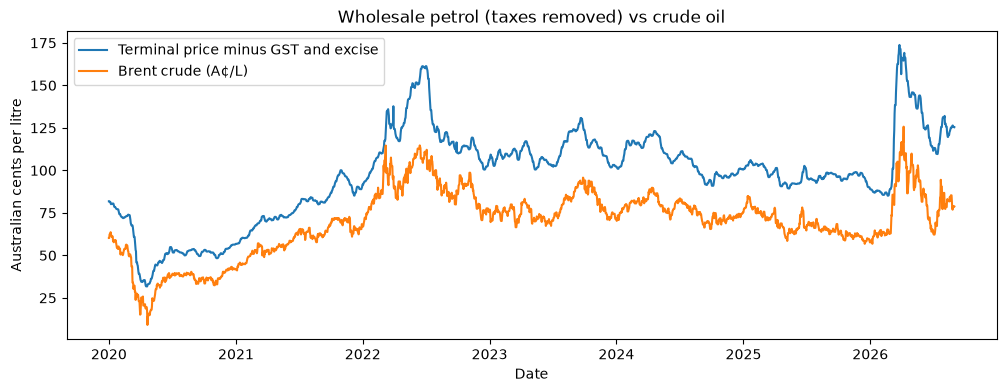

In [144]:
daily["terminal_price_ex_tax"] = daily["terminal_price"] / 1.1 - daily["excise"]

plt.figure(figsize=(12,4))
plt.plot(daily["date"], daily["terminal_price_ex_tax"], label="Terminal price minus GST and excise")
plt.plot(daily["date"], daily["brent_aud_cpl"], label="Brent crude (A¢/L)")
plt.title("Wholesale petrol (taxes removed) vs crude oil")
plt.xlabel("Date"); plt.ylabel("Australian cents per litre")
plt.legend(); plt.show()
# shows how crude oil and wholesale petrol prices move (very similar shape (expected), but slight offset to account for marign (production costs) )

In [145]:
print(daily.shape)
daily.describe().round(2)
#shows summary stats of the table (i.e IQR, mean, std, range for all variables). table has 2435 rows and 7 columns

(2435, 7)


,date,terminal_price,audusd,brent_usd,excise,brent_aud_cpl,terminal_price_ex_tax
count,2435,2435.00,2435.00,2435.00,2435.00,2435.00,2435.00
mean,2023-05-02 00:00:00,155.57,0.69,75.92,44.03,69.76,97.40
min,2020-01-01 00:00:00,81.40,0.56,9.12,20.60,9.09,31.70
25%,2021-08-31 12:00:00,138.30,0.65,66.70,42.30,61.10,83.03
50%,2023-05-02 00:00:00,162.90,0.68,76.10,46.00,71.57,100.06
75%,2024-12-30 12:00:00,172.90,0.72,86.33,50.60,81.34,113.48
max,2026-08-31 00:00:00,249.00,0.80,138.21,53.70,125.70,173.76
std,NaN,28.16,0.04,20.50,8.73,18.93,26.44


In [146]:
# Correlation coefficient between the factors  
daily[["terminal_price", "brent_usd", "audusd", "brent_aud_cpl", "excise"]].corr().round(2)

,terminal_price,brent_usd,audusd,brent_aud_cpl,excise
terminal_price,1.00,0.84,-0.35,0.90,0.07
brent_usd,0.84,1.00,0.04,0.98,-0.34
audusd,-0.35,0.04,1.00,-0.16,-0.38
brent_aud_cpl,0.90,0.98,-0.16,1.00,-0.25
excise,0.07,-0.34,-0.38,-0.25,1.00


In [147]:
#looks inside data folder for all fuelcheck data, some have different naming conventions, thus commonalities between files is used to source data
all_files = glob.glob("data/**/*", recursive=True)
files = sorted(f for f in all_files
               if "pricehistory" in os.path.basename(f).lower().replace("_", "")    # keeps fuelcheck data only as that has a common name 'pricehistory' or 'price_history'
               ) 

print("FuelCheck files found:", len(files))
print("  Excel:", sum(f.endswith(".xlsx") for f in files), "| CSV:", sum(f.endswith(".csv") for f in files))
print(files[:3], "...", files[-3:])

FuelCheck files found: 80
  Excel: 72 | CSV: 8
['data/fuel type data/fuelcheck_jan_2020_present/fuelcheck_pricehistory_apr2024.xlsx', 'data/fuel type data/fuelcheck_jan_2020_present/fuelcheck_pricehistory_apr2025.xlsx', 'data/fuel type data/fuelcheck_jan_2020_present/fuelcheck_pricehistory_apr2026.xlsx'] ... ['data/fuel type data/fuelcheck_jan_2020_present/price_history_checks_sep2022.xlsx', 'data/fuel type data/fuelcheck_jan_2020_present/price_history_checks_sep23.xlsx', 'data/fuel type data/fuelcheck_jan_2020_present/price_history_checks_september2021.xlsx']


In [148]:
def load_fuelcheck(path):
    # Read every cell, no column names yet
    if path.endswith(".csv"):
        raw = pd.read_csv(path, header=None, dtype=str, encoding="utf-8-sig")
    else:
        raw = pd.read_excel(path, header=None)

    # Find header row and use everything below header for data frame, transfer column names to new df.
    first_col = raw.iloc[:, 0].astype(str).str.strip()
    header_row = raw.index[first_col == "ServiceStationName"][0]

    df = raw.iloc[header_row + 1:].copy()                        # everything below header 
    df.columns = raw.iloc[header_row].astype(str).str.strip()    # use row column names for new dataframe

    # Old files: merged cells are blank -> copy the value from the row above
    fill_cols = ["ServiceStationName", "Address", "Suburb", "Postcode", "Brand", "FuelCode", "PriceUpdatedDate"]
    df[fill_cols] = df[fill_cols].ffill()

    # Keep suburb and fuel
    is_suburb = df["Suburb"].astype(str).str.upper().str.strip() == SUBURB
    is_fuel   = df["FuelCode"].astype(str).str.strip() == FUEL
    df = df[is_suburb & is_fuel]

    return df[["ServiceStationName", "Address", "PriceUpdatedDate", "Price"]]



In [149]:
#combines all 80 Blacktown U91 price changes files into 1 file
SAVED = "data/blacktown_u91_price_changes.csv"

if os.path.exists(SAVED):
    changes = pd.read_csv(SAVED)
    print("Loaded saved file:", SAVED)
else:
    parts = []
    for f in files:
        part = load_fuelcheck(f)
        parts.append(part)
        print(f"{os.path.basename(f):45s} {len(part):4d} rows")    # progress, one line per file
    changes = pd.concat(parts, ignore_index=True)
    changes.to_csv(SAVED, index=False)
    print("Saved", SAVED)

print("Total Blacktown U91 price changes:", len(changes))
changes.head()

Loaded saved file: data/blacktown_u91_price_changes.csv
Total Blacktown U91 price changes: 13073


,ServiceStationName,Address,PriceUpdatedDate,Price
0,EG Ampol Blacktown,"41 - 43 Third Avenue, Blacktown NSW 2148",2024-04-02 06:36:17,186.9
1,Speedway Sunnyholt,"162 Sunnyholt Rd, Blacktown NSW 2148",2024-04-02 08:14:24,184.7
2,METRO SUNNYHOLT RD BLACKTOWN,"7 148 Sunnyholt Road, BLACKTOWN NSW 2148",2024-04-02 09:33:05,184.7
3,Coles Express Blacktown,"132-136 Sunnyholt Road, Blacktown NSW 2148",2024-04-02 11:30:52,185.9
4,7-Eleven Blacktown,"62 Walters Road, Blacktown NSW 2148",2024-04-02 11:36:21,185.9


## 11. Clean the price changes
**Dates:** old files store dates as text with AM/PM (`1/04/2021 12:10:33 AM`), new Excel and most CSV files as `2024-04-01 00:09:48`, and at least one CSV (June 2025) as `2/06/2025 11:25` (day first, 24-hour clock, no seconds). We parse each style with its **exact format**, the same lesson as the September 2016 bug in the NSW energy data: never let pandas guess day vs month.

In [150]:
text = changes["PriceUpdatedDate"].astype(str).str.strip()

# Three types of date formats: yyyy/mm/dd 24hr time, dd/mm/yyyy AM/PM, dd/mm/yyyy 24hr time
ampm  = text.str.contains("AM|PM")              # 1/04/2021 12:10:33 AM (.xls)
year_first   = text.str.match(r"^\d{4}-")              # 2024-04-01 00:09:48 (.xlsx)
day_first = ~ampm & ~year_first                      # 2/06/2025 11:25 (.csv)

#gives list of AM/PM times, year first, day first and june times
ampm_times  = pd.to_datetime(text.where(ampm),  format="%d/%m/%Y %I:%M:%S %p", errors="coerce")
year_first_times   = pd.to_datetime(text.where(year_first),   format="ISO8601",              errors="coerce")
june_times = pd.to_datetime(text.where(day_first), format="%d/%m/%Y %H:%M",       errors="coerce") #june 2025 times 24hr without seconds
changes["time"] = ampm_times.fillna(year_first_times).fillna(june_times)     # each row gets whichever version worked

print("AM/PM dates:", ampm.sum(), "| year-first dates:", year_first.sum(), "| day-first 24-hour dates:", day_first.sum())
print("Dates that failed to parse:", changes["time"].isna().sum())
print("Range:", changes["time"].min(), "to", changes["time"].max())

AM/PM dates: 6003 | year-first dates: 6602 | day-first 24-hour dates: 468
Dates that failed to parse: 0
Range: 2020-01-01 22:32:16 to 2026-08-31 20:50:55


In [151]:
changes["Price"] = pd.to_numeric(changes["Price"], errors="coerce")
#uses station address as identifier as different brands occur at different stations 

street = changes["Address"].astype(str).str.upper().str.split(",").str[0]       
street = street.str.replace(" ROAD", " RD").str.split().str.join(" ")          
same_site = {"7 148 SUNNYHOLT RD": "148 SUNNYHOLT RD",           # accounts for different ways to write address
             "132 SUNNYHOLT RD":   "132-136 SUNNYHOLT RD"}
changes["station"] = street.replace(same_site)

print("Missing:\n", changes[["time", "Price", "station"]].isna().sum())
print("Exact duplicate rows:", changes.duplicated(subset=["station", "time", "Price"]).sum())
changes = changes.dropna(subset=["time", "Price"]).drop_duplicates(subset=["station", "time", "Price"])

Missing:
 time       0
Price      0
station    0
dtype: int64
Exact duplicate rows: 359


In [152]:
# SHows all 11 Blacktown station addresses, number of price changes during period, Service station brands that have been at that address
changes.groupby("station")["ServiceStationName"].agg(["count", "unique"])

,count,unique
station,,
132-136 SUNNYHOLT RD,988,"[Coles Express Blacktown, Shell Reddy Express..."
140 FLUSHCOMBE RD,1079,"[METRO PETROLEUM BLACKTOWN FLUSHCOMBE, Metro F..."
143 KILDARE RD,612,[Budget Blacktown]
148 SUNNYHOLT RD,1036,"[METRO SUNNYHOLT RD BLACKTOWN, Metro Sunnyholt..."
162 SUNNYHOLT RD,983,"[Speedway Sunnyholt, BP Blacktown]"
175 RICHMOND RD,1560,[7-Eleven Blacktown]
354 CORNER FLUSHCOMBE RD & MYRTLE STREET,978,[7-Eleven Blacktown]
41 - 43 THIRD AVENUE,1328,"[EG Ampol Blacktown, Caltex Woolworths Blacktown]"
62 WALTERS RD,1793,[7-Eleven Blacktown]


In [153]:
# Outlier check, anything outside 80-400 c/L is considered invalid for U91 Blacktown data
print(changes["Price"].describe().round(1))
invalid_pump_price = ~changes["Price"].between(80, 400) #prices below the min and above the max are considered invalid 
print("Impossible prices removed:", invalid_pump_price.sum())
changes = changes[~invalid_pump_price]

count    12714.0
mean       171.1
std         29.1
min         78.0
25%        158.4
50%        174.9
75%        189.9
max        259.9
Name: Price, dtype: float64
Impossible prices removed: 1


In [154]:
day = changes["time"].dt.normalize()                 # keeps date only
changes = changes[(day >= START) & (day <= END)]      # keep changes from 1 Jan 2020 to 31 Aug 2026 

# Tests to make sure all months have price changes, if a month has 0 price changes, implied that data is missing or wrong
per_month = changes.groupby(changes["time"].dt.to_period("M")).size()
all_months = pd.period_range(START, END, freq="M")
missing_months = [str(m) for m in all_months if m not in per_month.index]
print("Months with NO data:", missing_months if missing_months else "none")
print("Fewest price changes in a month:", per_month.min(), "| most:", per_month.max())



Months with NO data: none
Fewest price changes in a month: 28 | most: 294


In [155]:
changes["date"] = changes["time"].dt.normalize()   # day of each change

# Last price at each station per day
end_of_day = (changes.sort_values("time")
                     .groupby(["date", "station"])["Price"].last()
                     .unstack())

# Every calendar day in the study period, uses forward fill to fill in the following days price using the last known price 'end_of_day'
all_days = pd.date_range(START, END, freq="D")
end_of_day = end_of_day.reindex(all_days).ffill(limit=30)

end_of_day.iloc[:10, :5]                                       

station,132-136 SUNNYHOLT RD,140 FLUSHCOMBE RD,143 KILDARE RD,148 SUNNYHOLT RD,162 SUNNYHOLT RD
2020-01-01,NaN,NaN,NaN,NaN,133.9
2020-01-02,136.9,NaN,NaN,NaN,133.9
2020-01-03,136.9,131.9,131.9,131.9,133.9
2020-01-04,136.9,129.9,129.9,129.9,133.9
2020-01-05,136.9,129.9,129.9,129.9,133.9
2020-01-06,135.9,129.9,129.9,129.9,133.9
2020-01-07,131.9,129.9,129.9,129.9,131.9
2020-01-08,131.9,129.9,129.9,129.9,131.9
2020-01-09,131.9,129.9,129.9,129.9,131.9
2020-01-10,131.9,142.9,129.9,128.9,131.9


In [156]:
#dataframe that gets descriptive stats form Blacktow U91 data
blacktown = pd.DataFrame({
    "date": all_days,
    "retail_price": end_of_day.mean(axis=1).values,               # average across the stations that have a price
    "stations": end_of_day.notna().sum(axis=1).values,            # how many stations went into the average
})
blacktown["stations"].describe()

count    2435.000000
mean       10.578234
std         0.692087
min         1.000000
25%        10.000000
50%        11.000000
75%        11.000000
max        11.000000
Name: stations, dtype: float64

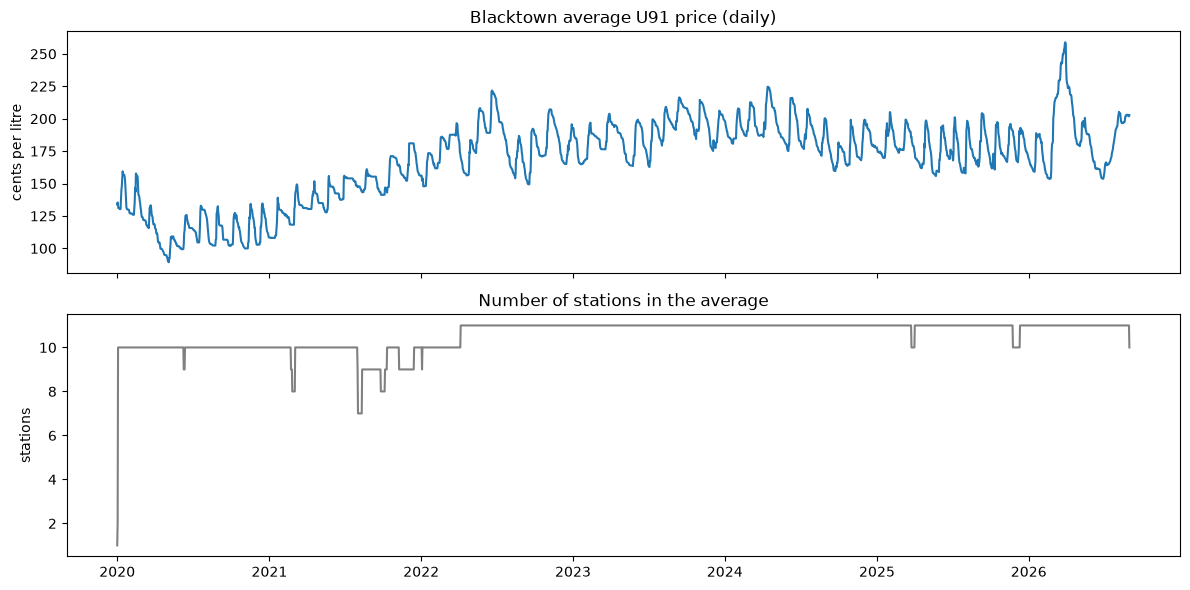

In [157]:
#plot shows blacktown price on avergae (across all 11 stations) over the period Jan 2020 - Aug 2026. No. of stations is also included as that can affect average. The no. of stations was not constant throughout the period
fig, ax = plt.subplots(2, 1, figsize=(12,6), sharex=True)
ax[0].plot(blacktown["date"], blacktown["retail_price"])
ax[0].set_title("Blacktown average U91 price (daily)"); ax[0].set_ylabel("cents per litre")
ax[1].plot(blacktown["date"], blacktown["stations"], color="grey")
ax[1].set_title("Number of stations in the average"); ax[1].set_ylabel("stations")
plt.tight_layout(); plt.show()

In [158]:
too_few = blacktown["stations"] < 3
print("Days with fewer than 3 stations (set to missing):", too_few.sum())
blacktown.loc[too_few, "retail_price"] = np.nan

Days with fewer than 3 stations (set to missing): 2


In [159]:
# merges  blacktown price and creates retail margin 
daily = daily.merge(blacktown, on="date", how="left")
daily["margin"] = daily["retail_price"] - daily["terminal_price"]
#shows value of factors for each of the days within the period as a check
print("Missing retail prices:", daily["retail_price"].isna().sum(), "of", len(daily), "days")
daily[["date", "retail_price", "terminal_price", "margin", "brent_aud_cpl", "excise", "stations"]].tail()

Missing retail prices: 2 of 2435 days


,date,retail_price,terminal_price,margin,brent_aud_cpl,excise,stations
2430,2026-08-27,202.627273,198.0,4.627273,78.966475,53.7,11
2431,2026-08-28,202.354545,197.1,5.254545,78.447966,53.7,11
2432,2026-08-29,201.900000,197.1,4.800000,78.447966,53.7,11
2433,2026-08-30,201.900000,197.1,4.800000,78.447966,53.7,11
2434,2026-08-31,202.800000,197.0,5.800000,78.776383,53.7,10


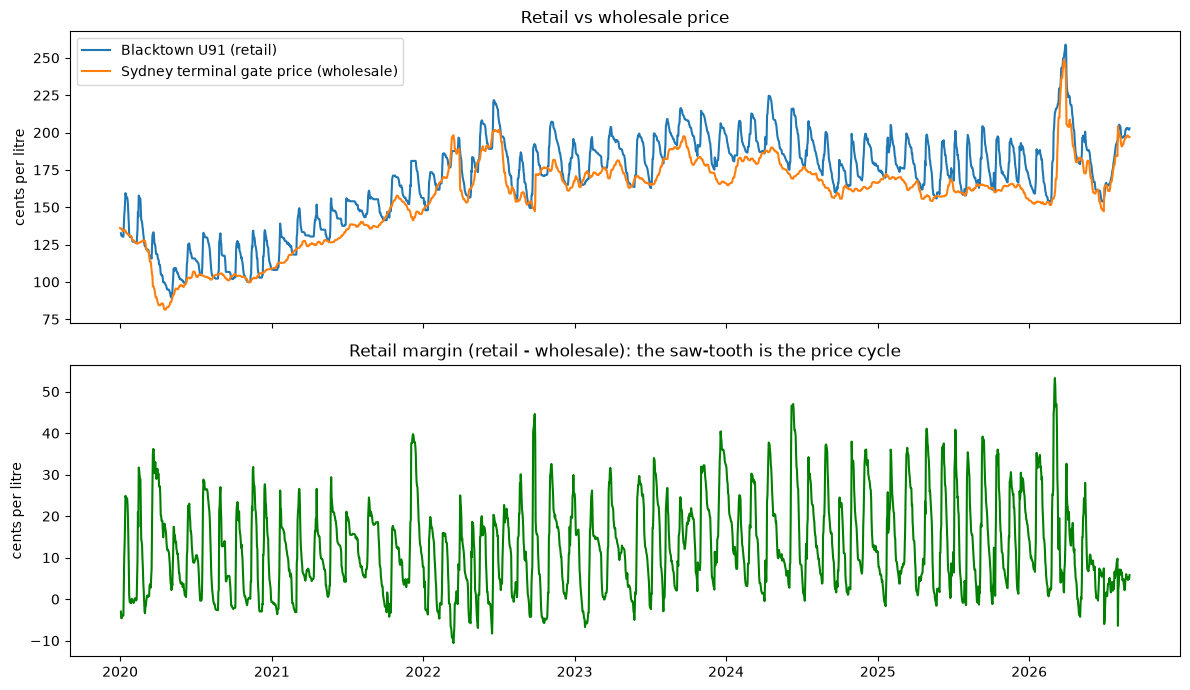

In [160]:
fig, ax = plt.subplots(2, 1, figsize=(12,7), sharex=True)
ax[0].plot(daily["date"], daily["retail_price"], label="Blacktown U91 (retail)")
ax[0].plot(daily["date"], daily["terminal_price"], label="Sydney terminal gate price (wholesale)")
ax[0].set_title("Retail vs wholesale price"); ax[0].set_ylabel("cents per litre"); ax[0].legend()
ax[1].plot(daily["date"], daily["margin"], color="green")
ax[1].set_title("Retail margin (retail - wholesale): the saw-tooth is the price cycle"); ax[1].set_ylabel("cents per litre")
plt.tight_layout(); plt.show()

In [161]:
# Correlation between price factors and retail price/margin 
daily[["retail_price", "terminal_price", "brent_aud_cpl", "audusd", "excise", "margin"]].corr().round(2)

,retail_price,terminal_price,brent_aud_cpl,audusd,excise,margin
retail_price,1.00,0.93,0.83,-0.39,0.13,0.40
terminal_price,0.93,1.00,0.90,-0.35,0.07,0.04
brent_aud_cpl,0.83,0.90,1.00,-0.16,-0.25,-0.01
audusd,-0.39,-0.35,-0.16,1.00,-0.38,-0.21
excise,0.13,0.07,-0.25,-0.38,1.00,0.17
margin,0.40,0.04,-0.01,-0.21,0.17,1.00


In [162]:
# Change in the Blacktown price from one day to the next
daily["change"] = daily["retail_price"].diff()

print("Days the price fell:          ", round((daily["change"] < 0).mean() * 100), "%")
print("Days it rose by more than 5c: ", round((daily["change"] > 5).mean() * 100), "%")
print("Average fall on a falling day:", round(daily.loc[daily["change"] < 0, "change"].mean(), 2), "c/L")
print("Average rise on a >5c day:    ", round(daily.loc[daily["change"] > 5, "change"].mean(), 2), "c/L")



Days the price fell:           58 %
Days it rose by more than 5c:  6 %
Average fall on a falling day: -1.36 c/L
Average rise on a >5c day:     9.4 c/L


In [163]:
# big rises are when the price change is greater than 5c/L (normally occuring during a restoration)
big_rise = daily["change"] > 5
# check to see if there was a big rise within the past 7 days, considers today to be apart of the restoration period too
rise_last_week = big_rise.shift(1, fill_value=False).astype(int).rolling(7, min_periods=1).max() > 0
daily["restoration"] = big_rise & ~rise_last_week

restore_dates = daily.loc[daily["restoration"], "date"]
cycle_length = restore_dates.diff().dt.days                 # days between one restoration and the next

print("Restorations found:", len(restore_dates), "| per year:", round(len(restore_dates) / (len(daily) / 365.25), 1))
print(cycle_length.describe().round(1))

Restorations found: 62 | per year: 9.3
count    61.0
mean     37.9
std      11.7
min       8.0
25%      33.0
50%      38.0
75%      45.0
max      67.0
Name: date, dtype: float64


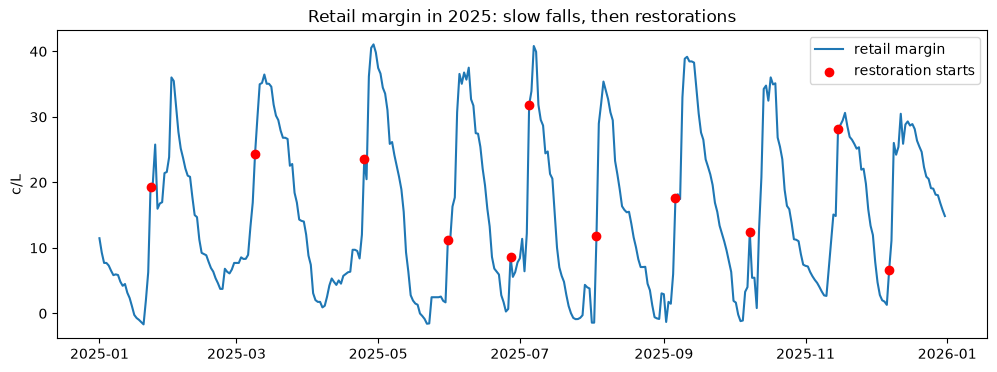

In [164]:
# One year of the margin, with each restoration marked
year = daily[(daily["date"] >= "2025-01-01") & (daily["date"] <= "2025-12-31")]
plt.figure(figsize=(12,4))
plt.plot(year["date"], year["margin"], label="retail margin")
plt.scatter(year.loc[year["restoration"], "date"], year.loc[year["restoration"], "margin"], color="red", label="restoration starts", zorder=3)
plt.title("Retail margin in 2025: slow falls, then restorations"); plt.ylabel("c/L"); plt.legend()
plt.show()

In [165]:
HORIZON = 3        # 3 days ahead, HORIZON = 2 for 2-day results


P = daily["retail_price"]
for d in [1, 2, 3, 7]:
    daily[f"change_{d}"] = P - P.shift(d)                     # shift(d) = the value d days earlier
daily["tgp_change_3"]   = daily["terminal_price"] - daily["terminal_price"].shift(3) # terminal price change over last 3 days
daily["tgp_change_7"]   = daily["terminal_price"] - daily["terminal_price"].shift(7) #terminal price change over last 7 days
daily["brent_change_7"] = daily["brent_aud_cpl"] - daily["brent_aud_cpl"].shift(7) # brent price change over last 7 days

# Days since the last restoration: count up by 1 each day, reset to 0 on a restoration day
count = np.nan
days_since = []
for r in daily["restoration"]:
    if r:
        count = 0
    elif not np.isnan(count):
        count = count + 1
    days_since.append(count)
daily["days_since_restoration"] = days_since

# TARGET: change in price over the next HORIZON days. shift(-HORIZON) = the value HORIZON days LATER.
daily["future_price"]  = P.shift(-HORIZON)
daily["target_change"] = daily["future_price"] - P
# change_1 = price change from yesterday, change_2 = price change from 2 days ago, ...
FEATURES = ["change_1", "change_2", "change_3", "change_7", "margin",
            "tgp_change_3", "tgp_change_7", "brent_change_7", "excise", "days_since_restoration"]
daily[["date"] + FEATURES + ["target_change"]].tail(8)

,date,change_1,change_2,change_3,change_7,margin,tgp_change_3,tgp_change_7,brent_change_7,excise,days_since_restoration,target_change
2427,2026-08-24,0.000000,1.036364,1.181818,5.363636,5.318182,0.7,3.7,-0.381301,53.7,107.0,-0.090909
2428,2026-08-25,0.363636,0.363636,1.400000,6.000000,5.281818,1.1,3.5,-6.780290,53.7,108.0,-0.727273
2429,2026-08-26,0.000000,0.363636,0.363636,5.727273,4.981818,1.4,2.9,-5.310081,53.7,109.0,-1.181818
2430,2026-08-27,-0.454545,-0.454545,-0.090909,4.272727,4.627273,0.6,2.1,-4.119994,53.7,110.0,-0.727273
2431,2026-08-28,-0.272727,-0.727273,-0.727273,0.818182,5.254545,-0.7,0.4,-6.871781,53.7,111.0,0.445455
2432,2026-08-29,-0.454545,-0.727273,-1.181818,0.218182,4.800000,-1.0,0.4,-6.871781,53.7,112.0,NaN
2433,2026-08-30,0.000000,-0.454545,-0.727273,-0.818182,4.800000,-0.9,0.4,-6.871781,53.7,113.0,NaN
2434,2026-08-31,0.900000,0.900000,0.445455,0.081818,5.800000,-0.1,-0.4,-2.564032,53.7,114.0,NaN


In [166]:
# All days must have all 10 inputs + target price over 3 days
model_data = daily.dropna(subset=FEATURES + ["target_change"]).copy()
# splits data period into training 2020-2024 and testing 
train = model_data[model_data["date"] <  "2025-01-01"]
test  = model_data[model_data["date"] >= "2025-01-01"]
print("Training days:", len(train), "(", train["date"].min().date(), "to", train["date"].max().date(), ")")
print("Test days:    ", len(test),  "(", test["date"].min().date(),  "to", test["date"].max().date(), ")")

Training days: 1818 ( 2020-01-10 to 2024-12-31 )
Test days:     605 ( 2025-01-01 to 2026-08-28 )


In [167]:
results = []        # we add one row per model, then compare them all at the end

def evaluate(name, predicted_change, actual_change):
    predicted_change = np.asarray(predicted_change)
    actual_change    = np.asarray(actual_change)
    mae = np.mean(np.abs(predicted_change - actual_change))

    moved = np.abs(actual_change) >= 1                       # ignore days where price movement is negligible
    if np.all(predicted_change == 0):
        direction = np.nan                                   # 0 change cannot predict direction
    else:
        direction = np.mean(np.sign(predicted_change[moved]) == np.sign(actual_change[moved])) * 100

    results.append({"model": name, "MAE (c/L)": round(mae, 2), "direction correct (%)": round(direction, 1)})
    print(f"{name}: MAE = {mae:.2f} c/L, direction correct =", "n/a" if np.isnan(direction) else f"{direction:.1f}%")
# baseline assumes no change for all test days, measures MAE and direction is not applicable as there is no change
evaluate("Baseline: no change", np.zeros(len(test)), test["target_change"])

Baseline: no change: MAE = 5.42 c/L, direction correct = n/a


In [168]:
def ode_rhs(s, P, C0, slope, k, m):
    # dP/dt = k * (C(s) + m - P) -> ODE , dP/dt = rate retail price changes per day
    return k * (C0 + slope * s + m - P)
#Euler solver of ODE
def euler(P0, C0, slope, k, m, days, dt):
    P, s = P0, 0.0
    for _ in range(round(days / dt)):
        P = P + dt * ode_rhs(s, P, C0, slope, k, m)
        s = s + dt
    return P
#RK4 solver of ODE
def rk4(P0, C0, slope, k, m, days, dt):
    P, s = P0, 0.0
    for _ in range(round(days / dt)):
        k1 = ode_rhs(s,          P,               C0, slope, k, m)
        k2 = ode_rhs(s + dt / 2, P + dt / 2 * k1, C0, slope, k, m)
        k3 = ode_rhs(s + dt / 2, P + dt / 2 * k2, C0, slope, k, m)
        k4 = ode_rhs(s + dt,     P + dt * k3,     C0, slope, k, m)
        P = P + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        s = s + dt
    return P

# P0, C0 and slope can be single numbers OR whole columns: numpy then solves the ODE for every day at once.
print("Check: price 190, wholesale 175 and flat, k = 0.1, m = 5  ->  in 3 days:",
      round(rk4(190, 175, 0, 0.1, 5, 3, 1), 2), "c/L")

Check: price 190, wholesale 175 and flat, k = 0.1, m = 5  ->  in 3 days: 187.41 c/L


In [169]:
# Recent wholesale trend: average change per day over the last 3 days
model_data["tgp_slope"] = model_data["tgp_change_3"] / 3
#split again to account for new column (tgp_slope) which is the terminal price change per day
train = model_data[model_data["date"] <  "2025-01-01"]
test  = model_data[model_data["date"] >= "2025-01-01"]

k_values = np.arange(0, 0.2001, 0.005)
m_values = np.arange(-10, 15.01, 0.5)
grid_mae = np.zeros((len(k_values), len(m_values)))

for i, k in enumerate(k_values):
    for j, m in enumerate(m_values):
        forecast = rk4(train["retail_price"].values, train["terminal_price"].values, train["tgp_slope"].values,
                       k, m, HORIZON, dt=1)
        grid_mae[i, j] = np.mean(np.abs(forecast - train["future_price"].values))

best_i, best_j = np.unravel_index(grid_mae.argmin(), grid_mae.shape)     # position of the smallest MAE
k_fit, m_fit = k_values[best_i], m_values[best_j]
print(f"Best fit: k = {k_fit:.3f} per day, m = {m_fit:.1f} c/L, training MAE = {grid_mae.min():.2f} c/L")
print(f"Half-life of a price gap: ln(2)/k = {np.log(2) / k_fit:.0f} days")

Best fit: k = 0.030 per day, m = -2.5 c/L, training MAE = 3.75 c/L
Half-life of a price gap: ln(2)/k = 23 days


In [170]:
# Same ODE forecast, but solved with Euler's method to compare with RK4
ode_euler_test = euler(test["retail_price"].values, test["terminal_price"].values, test["tgp_slope"].values,
                       k_fit, m_fit, HORIZON, dt=1)
evaluate("ODE pass-through (Euler)", ode_euler_test - test["retail_price"].values, test["target_change"])

ODE pass-through (Euler): MAE = 4.96 c/L, direction correct = 65.3%


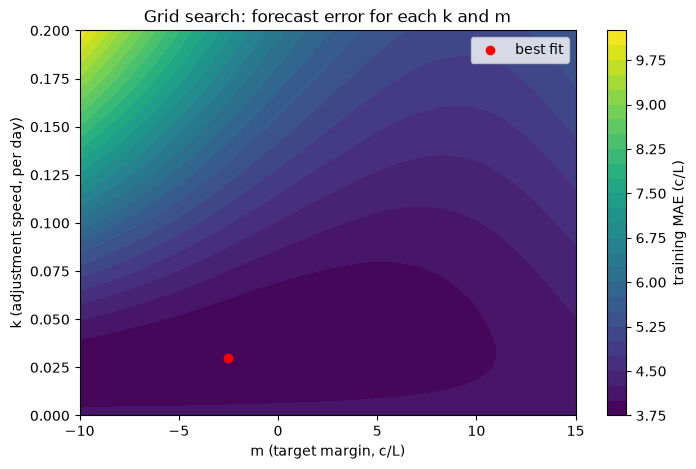

In [171]:
#contour plot showing the MAE via each combination of k and m
plt.figure(figsize=(8,5))
cs = plt.contourf(m_values, k_values, grid_mae, levels=30)
plt.colorbar(cs, label="training MAE (c/L)")
plt.scatter(m_fit, k_fit, color="red", label="best fit")
plt.xlabel("m (target margin, c/L)"); plt.ylabel("k (adjustment speed, per day)")
plt.title("Grid search: forecast error for each k and m"); plt.legend()
plt.show()

In [172]:
# ODE forecast for the test period, using k and m fitted on the training period only
ode_forecast_test = rk4(test["retail_price"].values, test["terminal_price"].values, test["tgp_slope"].values,
                        k_fit, m_fit, HORIZON, dt=1)
evaluate("ODE pass-through (RK4)", ode_forecast_test - test["retail_price"].values, test["target_change"])
#predicted 4.95c/l off the 3-day change (average error), 65.6% of the time it predicted correctly that it would increase or decrease on days where the price changed by at least 1c/L

ODE pass-through (RK4): MAE = 4.95 c/L, direction correct = 65.6%


In [173]:
def exact(P0, C0, slope, k, m, s):
    return C0 + m + slope * s - slope / k + (P0 - C0 - m + slope / k) * np.exp(-k * s)

# Check: price 200 c/L, wholesale 170 c/L and rising 0.5 c/L per day, fitted k and m, solved 40 days ahead
P0, C0, slope, days = 200, 170, 0.5, 40
true_value = exact(P0, C0, slope, k_fit, m_fit, days)

step_sizes = [8, 4, 2, 1, 0.5]
rows = []
for dt in step_sizes:
    rows.append({"step size dt (days)": dt,
                 "Euler error (c/L)": abs(euler(P0, C0, slope, k_fit, m_fit, days, dt) - true_value),
                 "RK4 error (c/L)":   abs(rk4(P0, C0, slope, k_fit, m_fit, days, dt) - true_value)})
accuracy = pd.DataFrame(rows)
print("Value after", days, "days:", round(true_value, 4), "c/L")
accuracy

Value after 40 days: 185.642 c/L


,step size dt (days),Euler error (c/L),RK4 error (c/L)
0,8.0,2.342382,6.004449e-04
1,4.0,1.115751,3.394172e-05
2,2.0,0.545159,2.017681e-06
3,1.0,0.269528,1.229882e-07
4,0.5,0.134016,7.591240e-09


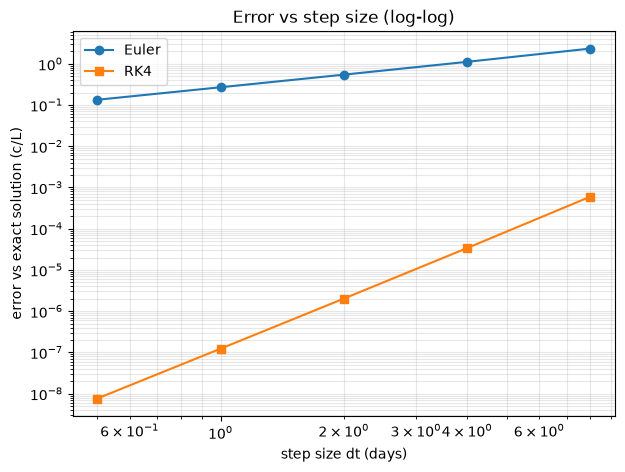

Measured order: Euler 1.03 (theory 1), RK4 4.07 (theory 4)


In [174]:
plt.figure(figsize=(7,5))
plt.loglog(accuracy["step size dt (days)"], accuracy["Euler error (c/L)"], "o-", label="Euler")
plt.loglog(accuracy["step size dt (days)"], accuracy["RK4 error (c/L)"],   "s-", label="RK4")
plt.xlabel("step size dt (days)"); plt.ylabel("error vs exact solution (c/L)")
plt.title("Error vs step size (log-log)"); plt.legend(); plt.grid(True, which="both", alpha=0.3)
plt.show()

# order of accuracy = slope of each line on the log-log plot, steeper slope means that the error decreases much quicker as the stepsize decreases 
euler_order = np.polyfit(np.log(accuracy["step size dt (days)"]), np.log(accuracy["Euler error (c/L)"]), 1)[0]
rk4_order   = np.polyfit(np.log(accuracy["step size dt (days)"]), np.log(accuracy["RK4 error (c/L)"]),   1)[0]
print(f"Measured order: Euler {euler_order:.2f} (theory 1), RK4 {rk4_order:.2f} (theory 4)")

In [175]:
# ODE forecast (as a change) for every day, using the k and m fitted on training data
model_data["ode_change"] = rk4(model_data["retail_price"].values, model_data["terminal_price"].values,
                               model_data["tgp_slope"].values, k_fit, m_fit, HORIZON, dt=1) - model_data["retail_price"].values
train = model_data[model_data["date"] <  "2025-01-01"]
test  = model_data[model_data["date"] >= "2025-01-01"]
FEATURES_ODE = FEATURES + ["ode_change"]

In [176]:
#linear regression model 
from sklearn.linear_model import LinearRegression
#fit on training data, predict 3-day chang for the testing period
linear = LinearRegression().fit(train[FEATURES], train["target_change"])
evaluate("Linear regression", linear.predict(test[FEATURES]), test["target_change"])

linear_ode = LinearRegression().fit(train[FEATURES_ODE], train["target_change"])
evaluate("Linear regression + ODE", linear_ode.predict(test[FEATURES_ODE]), test["target_change"])

# Coefficients: how much each feature moves the forecast (c/L per unit of the feature)
pd.Series(linear.coef_, index=FEATURES).round(3)

Linear regression: MAE = 4.41 c/L, direction correct = 77.0%
Linear regression + ODE: MAE = 4.41 c/L, direction correct = 77.0%


change_1                  0.323
change_2                  0.205
change_3                  0.126
change_7                  0.111
margin                   -0.282
tgp_change_3              0.030
tgp_change_7             -0.091
brent_change_7            0.047
excise                    0.059
days_since_restoration    0.025
dtype: float64

In [177]:
from sklearn.ensemble import RandomForestRegressor

# min sample leaf=5: each leaf needs at least 5 days, so trees can't memorise singular days
# random_state=0: the same "random" trees are run every run, so results are repeatable
forest = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0).fit(train[FEATURES], train["target_change"])
evaluate("Random forest", forest.predict(test[FEATURES]), test["target_change"])

forest_ode = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0).fit(train[FEATURES_ODE], train["target_change"])
evaluate("Random forest + ODE", forest_ode.predict(test[FEATURES_ODE]), test["target_change"])

Random forest: MAE = 4.74 c/L, direction correct = 80.7%
Random forest + ODE: MAE = 4.73 c/L, direction correct = 80.1%


## 21. Results

In [178]:
# combines all results that have been evaluated into a single table
results_table = pd.DataFrame(results).drop_duplicates("model", keep="last").set_index("model")
#the improvement each model is compared to baseline
results_table["improvement on baseline (%)"] = (
    (1 - results_table["MAE (c/L)"] / results_table.loc["Baseline: no change", "MAE (c/L)"]) * 100).round(1)
print(f"Forecasting {HORIZON} days ahead, test period 2025 - Aug 2026")
results_table

Forecasting 3 days ahead, test period 2025 - Aug 2026


,MAE (c/L),direction correct (%),improvement on baseline (%)
model,,,
Baseline: no change,5.42,NaN,0.0
ODE pass-through (Euler),4.96,65.3,8.5
ODE pass-through (RK4),4.95,65.6,8.7
Linear regression,4.41,77.0,18.6
Linear regression + ODE,4.41,77.0,18.6
Random forest,4.74,80.7,12.5
Random forest + ODE,4.73,80.1,12.7


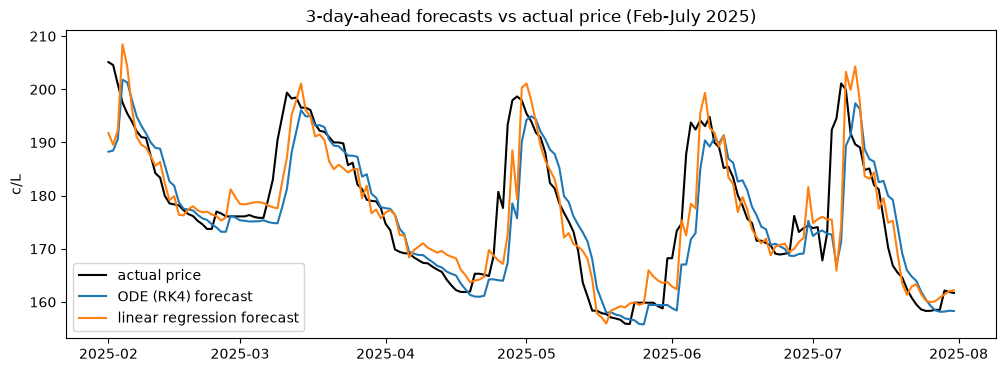

In [179]:
# Forecast vs actual over 6 months of the test period (better view of trend)
test_plot = test.copy()
test_plot["linear_forecast"] = test_plot["retail_price"] + linear.predict(test[FEATURES])
test_plot["ode_forecast"]    = test_plot["retail_price"] + test_plot["ode_change"]
test_plot["forecast_for"]    = test_plot["date"] + pd.Timedelta(days=HORIZON)     # the day each forecast is FOR

window = test_plot[(test_plot["forecast_for"] >= "2025-02-01") & (test_plot["forecast_for"] <= "2025-07-31")]
actual = daily[(daily["date"] >= "2025-02-01") & (daily["date"] <= "2025-07-31")]
#plots actual, and 3-day forecasts with linear regression and RK4 to compare with actual historical data
plt.figure(figsize=(12,4))
plt.plot(actual["date"], actual["retail_price"], color="black", label="actual price")
plt.plot(window["forecast_for"], window["ode_forecast"], label="ODE (RK4) forecast")
plt.plot(window["forecast_for"], window["linear_forecast"], label="linear regression forecast")
plt.title(f"{HORIZON}-day-ahead forecasts vs actual price (Feb-July 2025)"); plt.ylabel("c/L"); plt.legend()
plt.show()

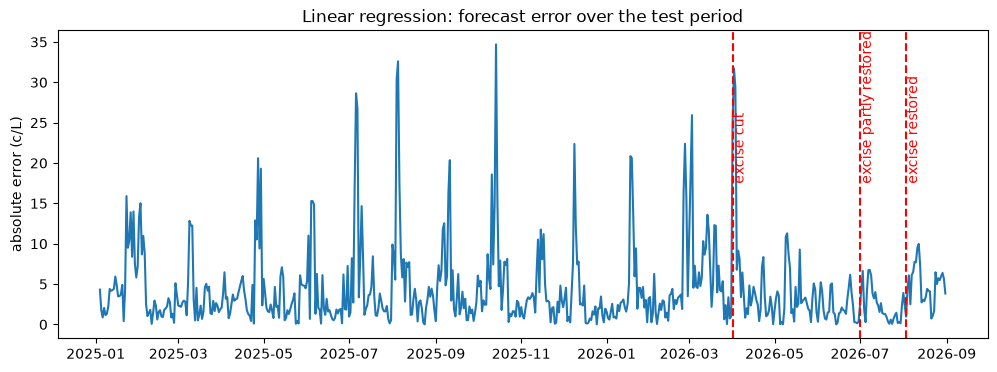

Mean error 2025: 4.5 c/L
Mean error 2026: 4.28 c/L


In [180]:
# Where the model fails, showing parts that cannot be predicted/forecasted - i.e. excise changes and sudden jumps (restorations)
test_plot["error"] = (test_plot["linear_forecast"] - test_plot["future_price"]).abs()
plt.figure(figsize=(12,4))
plt.plot(test_plot["forecast_for"], test_plot["error"])
for d, label in [("2026-04-01", "excise cut"), ("2026-07-01", "excise partly restored"), ("2026-08-03", "excise restored")]:
    plt.axvline(pd.Timestamp(d), color="red", linestyle="--"); plt.text(pd.Timestamp(d), test_plot["error"].max() * 0.5, " " + label, rotation=90, color="red")
plt.title("Linear regression: forecast error over the test period"); plt.ylabel("absolute error (c/L)")
plt.show()

print("Mean error 2025:", round(test_plot.loc[test_plot["forecast_for"].dt.year == 2025, "error"].mean(), 2), "c/L")
print("Mean error 2026:", round(test_plot.loc[test_plot["forecast_for"].dt.year == 2026, "error"].mean(), 2), "c/L")

In [181]:
import time
import cProfile, pstats

def time_it(func, repeats=3):
    '''Run func() `repeats` times and return the FASTEST run time in seconds.
    Taking the fastest of several runs reduces noise from other programs running on the computer.'''
    best = float("inf")
    for _ in range(repeats):
        start = time.perf_counter()
        func()
        best = min(best, time.perf_counter() - start)
    return best

perf = []      # summary rows collected 

### 23.1 Loading the FuelCheck data: raw files vs saved CSV
Reading all 80 raw files takes minutes, so Step 10 does it **once** and saves the Blacktown rows to a small CSV. Here we time one raw file, estimate the total for all files, and compare with loading the CSV. The **profiler** then shows *where* the time goes inside `load_fuelcheck`.

In [182]:
#loading FuelCheck data comparing raw data vs combined .csv file to compare process speed and memory used
t_cache = time_it(lambda: pd.read_csv(SAVED))
cache_mb = pd.read_csv(SAVED).memory_usage(deep=True).sum() / 1e6

xlsx_files = [f for f in files if f.endswith(".xlsx")]
csv_files  = [f for f in files if f.endswith(".csv")]

if len(files) > 0:
    total_est, total_rows, total_mb = 0, 0, 0
    for group in [xlsx_files, csv_files]:
        if len(group) == 0:
            continue
        one_file = group[0]                                              # time ONE file of this type ...
        t_one = time_it(lambda: load_fuelcheck(one_file), repeats=1)
        if one_file.endswith(".xlsx"):
            raw = pd.read_excel(one_file, header=None)
        else:
            raw = pd.read_csv(one_file, header=None, dtype=str, encoding="utf-8-sig")
        raw_mb = raw.memory_usage(deep=True).sum() / 1e6                 # memory of one unfiltered file
        total_est += t_one * len(group)                                  # ... and scale up to all files of that type
        total_mb  += raw_mb * len(group)
        print(f"{one_file.split('.')[-1].upper()} file: {len(raw):,} rows, {raw_mb:.0f} MB, {t_one:.2f} s to load and filter "
              f"(x {len(group)} files)")
    print(f"All {len(files)} raw files (estimate): {total_est:.0f} s (about {total_est / 60:.1f} min), "
          f"about {total_mb / 1000:.1f} GB if all rows were kept")
    print(f"Saved CSV: {len(changes):,} rows, {cache_mb:.1f} MB, {t_cache:.3f} s to load")
    print(f"Speed-up from caching: about {total_est / t_cache:,.0f} times faster; memory about {total_mb / cache_mb:,.0f} times smaller")
    perf.append({"part": "Load FuelCheck (raw files, estimate)", "time (s)": round(total_est, 1)})
else:
    print("Raw files not available - only the cached CSV can be timed.")
    print(f"Saved CSV: {cache_mb:.1f} MB, {t_cache:.3f} s to load")
perf.append({"part": "Load FuelCheck (saved CSV)", "time (s)": round(t_cache, 3)})

XLSX file: 59,539 rows, 27 MB, 5.00 s to load and filter (x 72 files)
CSV file: 70,325 rows, 35 MB, 0.18 s to load and filter (x 8 files)
All 80 raw files (estimate): 361 s (about 6.0 min), about 2.2 GB if all rows were kept
Saved CSV: 12,713 rows, 3.1 MB, 0.015 s to load
Speed-up from caching: about 23,639 times faster; memory about 720 times smaller


In [183]:
# find the functions take the time when loading one raw Excel file? (top 8, by cumulative time) - profiler
if len(xlsx_files) > 0:
    profiler = cProfile.Profile()
    profiler.enable()
    load_fuelcheck(xlsx_files[0])
    profiler.disable()
    pstats.Stats(profiler).strip_dirs().sort_stats("cumulative").print_stats(8)

         11590313 function calls (11587907 primitive calls) in 9.721 seconds

   Ordered by: cumulative time
   List reduced from 1042 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      2/1    0.003    0.001    9.718    9.718 2424679259.py:1(load_fuelcheck)
      2/1    0.002    0.001    9.513    9.513 _base.py:162(read_excel)
        1    0.000    0.000    9.285    9.285 _base.py:1630(parse)
        1    0.000    0.000    9.285    9.285 _base.py:700(parse)
        1    0.315    0.315    9.194    9.194 _openpyxl.py:614(get_sheet_data)
    59540    0.132    0.000    8.123    0.000 _read_only.py:60(_cells_by_row)
    59540    0.557    0.000    7.156    0.000 _reader.py:125(parse)
    59539    0.486    0.000    3.476    0.000 _reader.py:282(parse_row)




In [184]:
#vectorising calc, solving ODE for all 1818 days at once using NumPy or solving each day one-by-one (non vectorised)
P_train = train["retail_price"].values
C_train = train["terminal_price"].values
s_train = train["tgp_slope"].values
#solves vectorised format (much quicker as it does all days at once)
def solve_vectorised():
    return rk4(P_train, C_train, s_train, k_fit, m_fit, HORIZON, dt=1)
#solves via loop, much slower as it processes each day separately
def solve_loop():
    return np.array([rk4(P_train[i], C_train[i], s_train[i], k_fit, m_fit, HORIZON, dt=1) for i in range(len(P_train))])
#comparison of time for vectorisation vs looping
t_vec  = time_it(solve_vectorised)
t_loop = time_it(solve_loop)
print("Same answers:", np.allclose(solve_vectorised(), solve_loop()))
print(f"Loop over {len(P_train)} days: {t_loop * 1000:.1f} ms | vectorised: {t_vec * 1000:.2f} ms | speed-up: {t_loop / t_vec:.0f}x")
perf.append({"part": "RK4 forecast, all training days (loop)", "time (s)": round(t_loop, 4)})
perf.append({"part": "RK4 forecast, all training days (vectorised)", "time (s)": round(t_vec, 5)})

Same answers: True
Loop over 1818 days: 21.6 ms | vectorised: 0.24 ms | speed-up: 89x


In [185]:
FLOPS_EULER, FLOPS_RK4 = 8, 42 # comes from flops per step calculated for Euler and RK4 respectively
TOLERANCE = 0.01 # required accuracy (c/L)
#test check using 40 days ahead, compare with exact solution
P0_ex, C0_ex, slope_ex, days_ex = 200, 170, 0.5, 40
true_ex = exact(P0_ex, C0_ex, slope_ex, k_fit, m_fit, days_ex)
#each solution to ODE starts at dt = 8, halves it until it reaches error less than 0.01c/L dt =8 as 40days/8 = 5 steps (1 business week)
rows = []
for name, solver, flops in [("Euler", euler, FLOPS_EULER), ("RK4", rk4, FLOPS_RK4)]:
    dt = 8.0
    while abs(solver(P0_ex, C0_ex, slope_ex, k_fit, m_fit, days_ex, dt) - true_ex) > TOLERANCE:
        dt = dt / 2                               # halve the step until the error is small enough
    steps = round(days_ex / dt)
    error = abs(solver(P0_ex, C0_ex, slope_ex, k_fit, m_fit, days_ex, dt) - true_ex)
    run_time = time_it(lambda: solver(P0_ex, C0_ex, slope_ex, k_fit, m_fit, days_ex, dt))
    rows.append({"method": name, "largest dt meeting 0.01 c/L": dt, "steps": steps,
                 "FLOPs": steps * flops, "error (c/L)": error, "time (ms)": round(run_time * 1000, 3)})
cost_table = pd.DataFrame(rows)
print(f"RK4 needs {cost_table.loc[0, 'FLOPs'] / cost_table.loc[1, 'FLOPs']:.0f} times fewer FLOPs than Euler for the same accuracy")
cost_table

RK4 needs 49 times fewer FLOPs than Euler for the same accuracy


,method,largest dt meeting 0.01 c/L,steps,FLOPs,error (c/L),time (ms)
0,Euler,0.03125,1280,10240,0.008333,0.456
1,RK4,8.00000,5,210,0.000600,0.010


In [186]:
n_pairs = len(k_values) * len(m_values)
steps   = round(HORIZON / 1)                       # dt = 1 day
grid_flops = n_pairs * len(P_train) * steps * FLOPS_RK4

def run_grid():
    for k in k_values:
        for m in m_values:
            rk4(P_train, C_train, s_train, k, m, HORIZON, dt=1)
# measures time taken for the grid search, then uses the time to find the FLOPs/s
t_grid = time_it(run_grid, repeats=1)
print(f"{n_pairs:,} (k, m) pairs x {len(P_train):,} days x {steps} steps")
print(f"About {grid_flops / 1e6:.0f} million FLOPs in {t_grid:.2f} s  ->  about {grid_flops / t_grid / 1e9:.2f} GFLOP/s")
perf.append({"part": f"Grid search ({n_pairs:,} pairs)", "time (s)": round(t_grid, 2)})

2,091 (k, m) pairs x 1,818 days x 3 steps
About 479 million FLOPs in 0.45 s  ->  about 1.07 GFLOP/s


In [187]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

t_lr = time_it(lambda: LinearRegression().fit(train[FEATURES], train["target_change"]))
perf.append({"part": "Train linear regression", "time (s)": round(t_lr, 4)})
#tests forests of size 10, 50, 100, 300, 500 trees
#tests time taken for each random forest and MAE using the testing data
#Displays law of diminishing returns after ~100 random trees on accuracy. @500 there is virtually 0 change to accuracy while taking much longer. 
rows = []
for n in [10, 50, 100, 300, 500]:
    start = time.perf_counter()
    model = RandomForestRegressor(n_estimators=n, min_samples_leaf=5, random_state=0).fit(train[FEATURES], train["target_change"])
    fit_time = time.perf_counter() - start
    mae = np.mean(np.abs(model.predict(test[FEATURES]) - test["target_change"]))
    rows.append({"trees": n, "train time (s)": round(fit_time, 2), "test MAE (c/L)": round(mae, 3)})
    if n == 300:
        perf.append({"part": "Train random forest (300 trees)", "time (s)": round(fit_time, 2)})
pd.DataFrame(rows)

,trees,train time (s),test MAE (c/L)
0,10,0.09,4.973
1,50,0.39,4.809
2,100,0.66,4.774
3,300,1.81,4.742
4,500,2.63,4.758


In [188]:
# Summary of all times for comparison
pd.DataFrame(perf)

,part,time (s)
0,"Load FuelCheck (raw files, estimate)",361.40000
1,Load FuelCheck (saved CSV),0.01500
2,"RK4 forecast, all training days (loop)",0.02160
3,"RK4 forecast, all training days (vectorised)",0.00024
4,"Grid search (2,091 pairs)",0.45000
5,Train linear regression,0.00330
6,Train random forest (300 trees),1.81000
